# 03 - Benchmark example (Section V)

Small benchmark network (10 nodes, 11 edges) where the exact optimum can be computed by brute force (138,240 configurations). Draws the configurations found for $\alpha_7$ (Fig. 5), the comparison of the algorithms and the GA evolution (Fig. 7) and the computation times (Table V).

**Choose the model variant** (see README, section *Two model variants*):

* `"dos"` (default) - integer DoS weights, linear models in $s_\mathcal{G}$ and $l_\mathcal{G}$ (ITSC-2024 calibration), exponential cost per metre.
* `"cscs"` - CycleRAP/CSCS weights, NNLS model $\tilde\theta=[0.41, 0.58, 0.45, 0.57]$ of Eq. (10), Cerema costs.
  With this model safety and comfort percentages are identical, because the prediction only depends on $l_\mathcal{G}$.

The GA and the Bayesian optimiser are stochastic: their results vary from run to run (seed fixed below for repeatability). MLCC and the brute-force optimum are deterministic.

In [1]:
import sys, json
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent / "src"))   # the cycling_tits package

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

from cycling_tits import CITIES, FIGURES, RESULTS, load_network, load_survey, pretty, Model, alphas
FIGURES.mkdir(exist_ok=True)

In [2]:
from cycling_tits.experiments import compare_algorithms, percents, ga_histories, time_table
from cycling_tits.plotting import comparison_bars, ga_evolution

PRESET = "dos"                # or "cscs"
TARGETS = ["safety", "comfort"]
METHODS = ['Optimal', 'MLCC', 'SGA', 'SGA-MLCC', 'Bayesian']
QUICK = False                  # True: very short GA / Bayesian runs, only to test the notebook
GENERATIONS, POP_SIZE, BAYES_CALLS = (5, 10, 10) if QUICK else (80, 50, 20)
SEED = 0
TAG = "_quick" if QUICK else ""
OUT = FIGURES / PRESET; OUT.mkdir(exist_ok=True)

In [3]:
results = {t: compare_algorithms("Benchmark", PRESET, t, METHODS, generations=GENERATIONS, pop_size=POP_SIZE,
                                bayes_calls=BAYES_CALLS, seed=SEED, tag=TAG)
           for t in TARGETS}

loaded cached results results\dos\Benchmark_safety.json
loaded cached results results\dos\Benchmark_comfort.json


## % of achievable improvement  $100\,|\hat y_{\omega_0}-\hat y(\omega^*)| / |\hat y_{FS}-\hat y_{\omega_0}|$

In [4]:
tables = {t: pd.DataFrame({m: percents(results[t], m) for m in METHODS}, index=[f"i={i}" for i in range(10)]).T.round(2)
          for t in TARGETS}
tables["safety"]

,i=0,i=1,i=2,i=3,i=4,i=5,i=6,i=7,i=8,i=9
Optimal,2.59,3.95,5.04,8.84,12.51,23.95,35.10,50.30,79.74,100.00
MLCC,2.32,2.32,2.32,6.60,6.60,20.78,28.96,42.61,65.12,100.00
SGA,2.59,3.95,4.47,8.84,11.10,23.92,35.00,49.70,77.48,100.00
SGA-MLCC,2.59,3.95,4.97,8.80,12.04,23.92,35.00,49.17,77.48,100.00
Bayesian,0.45,0.45,0.66,0.66,4.82,4.82,12.97,30.47,30.47,30.47


In [5]:
tables["comfort"]

,i=0,i=1,i=2,i=3,i=4,i=5,i=6,i=7,i=8,i=9
Optimal,2.38,3.64,4.14,8.25,11.73,23.74,34.99,50.30,79.97,100.00
MLCC,2.31,2.31,2.31,6.66,6.66,21.07,29.34,43.42,66.47,100.00
SGA,2.38,3.64,3.84,8.25,10.89,23.70,34.99,50.30,78.33,100.00
SGA-MLCC,2.38,3.64,4.14,8.25,11.48,23.70,34.99,49.56,79.05,100.00
Bayesian,0.36,0.36,0.48,0.48,4.12,4.12,12.36,29.73,29.73,29.73


## Fig. 7 (a) - comparison of the algorithms (plain = safety, hatched = comfort)

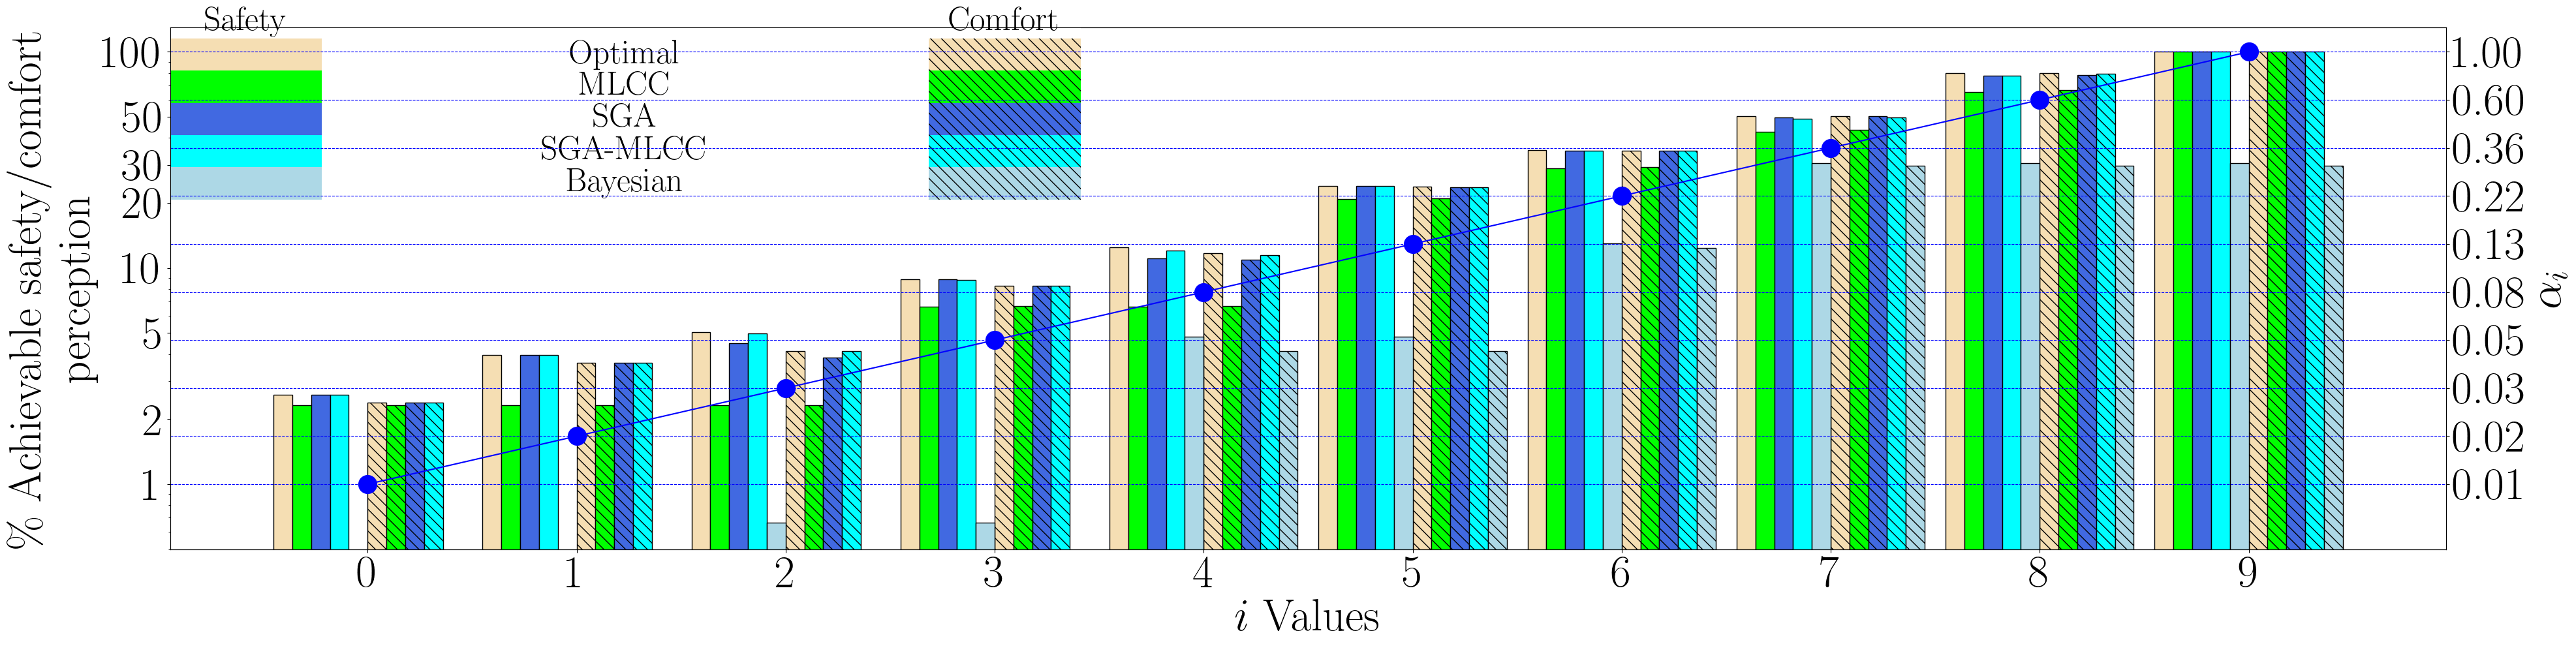

In [6]:
comparison_bars({m: percents(results["safety"], m) for m in METHODS},
                {m: percents(results["comfort"], m) for m in METHODS},
                outfile=OUT / "maximize_safety_academic_example_LCC.png", methods=METHODS);

## Fig. 7 (b), (c) - evolution of SGA and SGA-MLCC over the generations (safety)

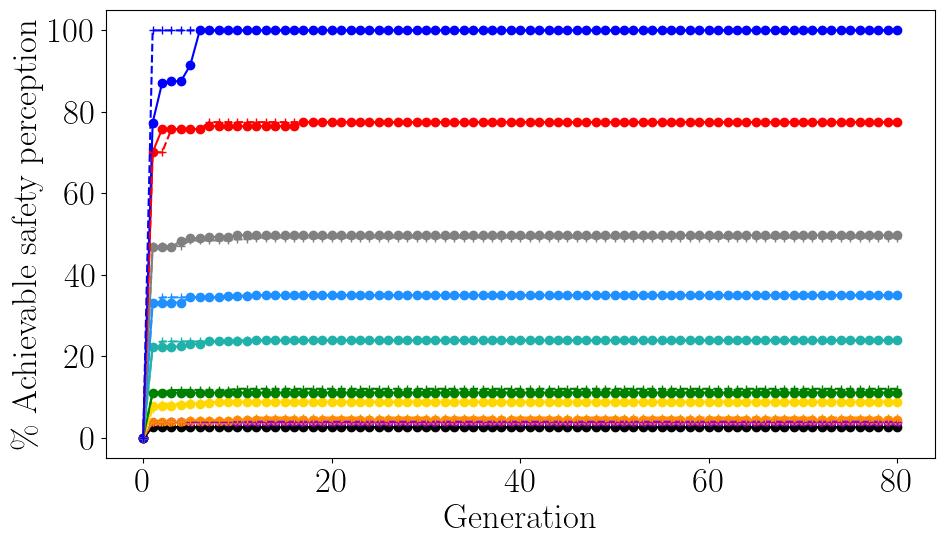

In [7]:
ga_evolution(ga_histories(results["safety"], "SGA"), ga_histories(results["safety"], "SGA-MLCC"),
             outfile=OUT / "Benchmark_comparation_GA_LCC_safety.png",
             legend_outfile=OUT / "Benchmark_comparation_GA_LCC_safety_legend.png");

## Table V - computation time

In [8]:
time_table(results["safety"], METHODS)

,i = 0,i = 1,i = 2,i = 3,i = 4,i = 5,i = 6,i = 7,i = 8,i = 9
Optimal,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m,8.86 m
MLCC,0.00849 s,0.00704 s,0.00476 s,0.00358 s,0.00771 s,0.00883 s,0.01 s,0.00802 s,0.0061 s,0.00666 s
SGA,10.90 s,9.79 s,9.70 s,9.97 s,11.18 s,12.29 s,12.17 s,13.00 s,13.78 s,3.48 s
SGA-MLCC,11.16 s,11.24 s,11.61 s,11.74 s,11.51 s,12.00 s,12.30 s,13.23 s,14.52 s,2.84 s
Bayesian,4.92 s,4.03 s,3.89 s,3.89 s,4.09 s,5.68 s,4.17 s,4.14 s,4.32 s,3.66 s


## Fig. 5 - benchmark network and the configurations found for safety with $\alpha_7 \approx 0.36$

B_max (Cerema) = 22011 EUR


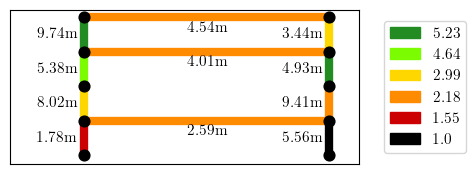

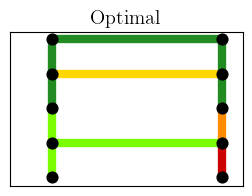

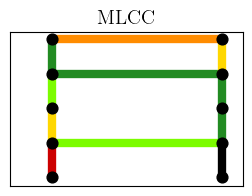

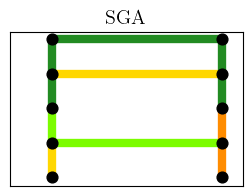

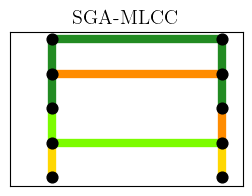

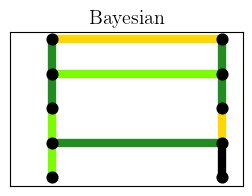

In [10]:
from cycling_tits.plotting import benchmark_network
G = load_network("Benchmark")
benchmark_network(G, outfile=OUT / "Plot_T_ITS_academic_example_original.png")
for m in METHODS:
    benchmark_network(G, results["safety"][m][7]["levels"], show_lengths=False, show_legend=False,
                      outfile=OUT / f"Plot_T_ITS_academic_example_{m.lower().replace('-', '_')}.png")
    plt.title(m)
print("B_max (Cerema) =", round(__import__('cycling_tits').max_budget(G, 'cerema')), "EUR")